In [31]:
# 1. Import libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.regularizers import L1
from tensorflow.keras.optimizers import Adam

In [32]:


data = pd.read_csv(r"D:\Downloads\DL DATASET\MNIST\mnist_784_csv.csv")


In [33]:
# Separate pixel values from labels

# Separate pixels and labels
X = data.drop('class', axis=1).values
# Normalize pixel values between 0 and 1
X = X.astype('float32') / 255.0
print("Dataset shape:", X.shape)

Dataset shape: (70000, 784)


In [34]:
# 2. Build Sparse Autoencoder

input_dim = X.shape[1]
encoding_dim = 64

# Encoder
input_layer = Input(shape=(input_dim,))

encoded = Dense(
    encoding_dim,
    activation='relu',
    activity_regularizer=L1(0.0000001)
)(input_layer)

# Decoder
decoded = Dense(
    input_dim,
    activation='sigmoid'
)(encoded)


In [35]:
# Create autoencoder model
autoencoder = Model(input_layer, decoded)

# Compile model
autoencoder.compile(
     optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy'
)

# Display model summary
autoencoder.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)           │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 784)                 │          50,960 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,200 (395.31 KB)

 Trainable params: 101,200 (395.31 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:

# 3. Train the autoencoder

history = autoencoder.fit(
    X, X,
    epochs=30,
    batch_size=256,
    shuffle=True,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.2506 - val_loss: 0.1658
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1488 - val_loss: 0.1335
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - loss: 0.1249 - val_loss: 0.1159
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.1108 - val_loss: 0.1051
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1019 - val_loss: 0.0980
Epoch 6/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 6s 27ms/step - loss: 0.0957 - val_loss: 0.0930
Epoch 7/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0913 - val_loss: 0.0893
Epoch 8/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0881 - val_loss: 0.0866
Epoch 9/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0858 - val_loss: 0.0848
Epoch 10/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - loss: 0.0842 - val_loss: 0.0834
Epoch 11/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - loss: 0.0830 - val_loss: 0.0825
Epoch 12/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 

In [38]:
# 9. Evaluate model
loss = autoencoder.evaluate(X, X)

print("Reconstruction Loss:", loss)


2188/2188 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0741
Reconstruction Loss: 0.07412104308605194


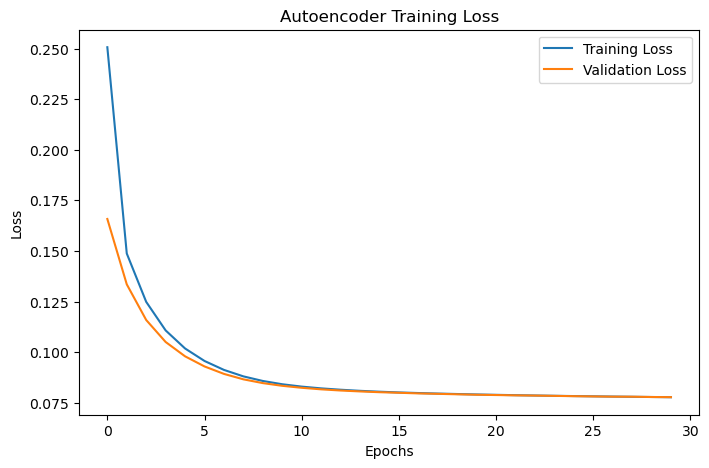

In [39]:
# 8. Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step


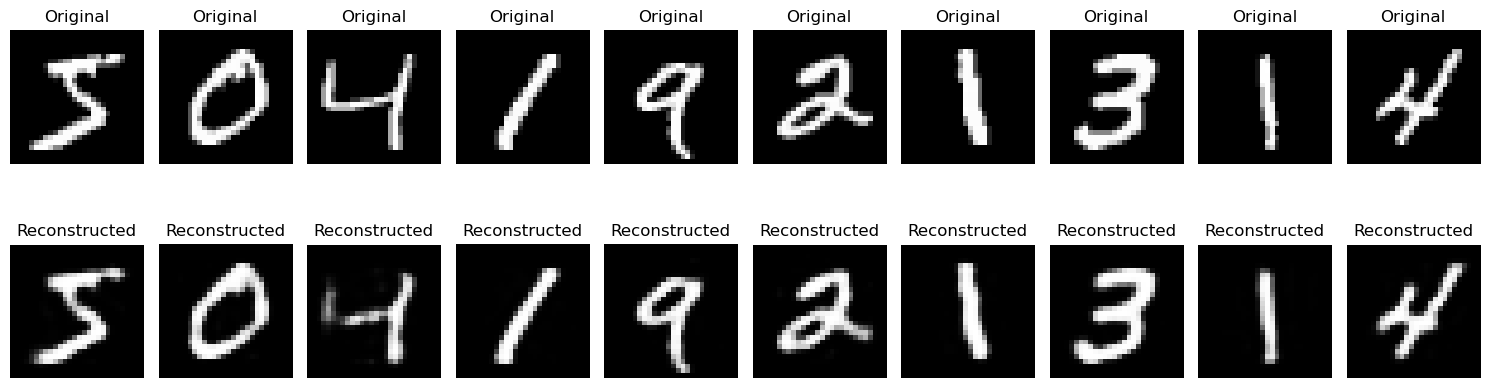

In [40]:
# 6. Reconstruct images
reconstructed = autoencoder.predict(X[:10])

# 7. Display original and reconstructed images
plt.figure(figsize=(15, 5))

for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()